In [1]:
from langchain_openai import ChatOpenAI
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=3)
tools = [tool]

llm = ChatOpenAI(model="gpt-4o")
llm_with_tools = llm.bind_tools(tools)


In [2]:
from typing import TypedDict, Annotated

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)

In [3]:
def chatbot(state: State):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}

graph_builder.add_node("chatbot", chatbot)

In [4]:
import json
from langchain.messages import ToolMessage

class BasicToolNode:
    """
        마지막 AIMessage에서 요청된 도구를 실행하는 노드
    """

    def __init__(self, tools: list) -> None:
        self.tools_by_name = {tool.name: tool for tool in tools}

    def __call__(self, inputs: dict):
        if messages := inputs.get("messages", []):
            message = messages[-1]
        else:
            raise ValueError("ERROR: 입력에 메시지가 없습니다.")
        
        outputs = []
        for tool_call in message.tool_calls:
            tool_result = self.tools_by_name[tool_call["name"]].invoke(
                tool_call["args"]
            )
            outputs.append(
                ToolMessage(
                    content=json.dumps(tool_result, ensure_ascii=False),
                    name=tool_call["name"],
                    tool_call_id=tool_call["id"]
                )
            )
        return {"messages": outputs}
    
tool_node = BasicToolNode(tools=[tool])
graph_builder.add_node("tools", tool_node)

In [5]:
def route_tools(
        state: State,
):
    """
    마지막 메시지에 도구 호출이 있는 경우, ToolNode로 라우팅하고 그렇지 않으면 END로 라우팅
    """
    if isinstance(state, list):
        ai_message = state[-1]
    elif messages := state.get("messages", []):
        ai_message = messages[-1]
    else:
        raise ValueError(f"ERROR: 입력에 메시지가 없습니다. 상태: {state}")
    
    if hasattr(ai_message, "tool_calls") and len(ai_message.tool_calls) > 0:
        return "tools"
    return END

graph_builder.add_conditional_edges(
    "chatbot",
    route_tools,
    {"tools": "tools", END: END}
)

In [6]:
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START, "chatbot")
graph = graph_builder.compile()

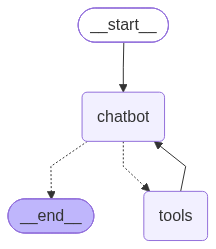

In [7]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [8]:
if __name__ == "__main__":
    try:
        image = graph.get_graph().draw_mermaid_png()
        with open("web_agent/graph.png", "wb") as f:
            f.write(image)
    except Exception:
        pass

    response = graph.invoke(
        {
            "messages": ["Langgraph가 무엇인가요?"]
        }
    )

    print(response)

{'messages': [HumanMessage(content='Langgraph가 무엇인가요?', additional_kwargs={}, response_metadata={}, id='ce3d4bfe-1974-4b6f-9781-a677679c1390'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 22, 'prompt_tokens': 1194, 'total_tokens': 1216, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_2079a33cc7', 'id': 'chatcmpl-E3wn4aZN5InkbuExsdbvWnh96Xpch', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f8306-ae9c-7a10-83ef-340f607d5c86-0', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'Langgraph란 무엇인가요?'}, 'id': 'call_ohsA97gQzKHmvaNF0PO6r0l6', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata=

In [9]:
def invoke():
    response = graph.invoke(
        {
            "messages": ["Langgraph가 무엇인가요?"]
        }
    )

    for msg in response["messages"]:
        msg.pretty_print()

if __name__ == "__main__":
    invoke()

================================ Human Message =================================

Langgraph가 무엇인가요?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_9goAMyymf9S8HUE31QTpbAc4)
 Call ID: call_9goAMyymf9S8HUE31QTpbAc4
  Args:
    query: Langgraph
================================= Tool Message =================================
Name: tavily_search

{"query": "Langgraph", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.ibm.com/think/topics/langgraph", "title": "What is LangGraph?", "content": "LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricat

In [ ]:
async def ainvoke():
    response = await graph.ainvoke(
        {
            "messages": ["Langgraph가 무엇인가요?"]
        }
    )

    for msg in response["messages"]:
        msg.pretty_print()

if __name__ == "__main__":
    import asyncio
    asyncio.run(ainvoke())

In [13]:
def stream():
    response = graph.stream(
        {
            "messages": ["Langgraph가 무엇인가요?"]
        }
    )
    for chunk in response:
        for node, state in chunk.items():
            print("---", node, "---")
            print(state)
            print("=" * 60)

if __name__ == "__main__":
    stream()

--- chatbot ---
{'messages': [AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 17, 'prompt_tokens': 1194, 'total_tokens': 1211, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_2079a33cc7', 'id': 'chatcmpl-E3wwvUqWZjElM45AgxqYsbbwc9kOb', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f8310-0547-75c0-9c6b-0a32b15f87fc-0', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'Langgraph'}, 'id': 'call_HmWyk8xQwYiXmUznp3N7rvEN', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1194, 'output_tokens': 17, 'total_tokens': 1211, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'o

In [14]:

def stream_values():
    response = graph.stream(
        {
            "messages": ["Langgraph가 무엇인가요?"]
        },
        stream_mode = "values"
    )

    for chunk in response:
        for state_key, state_value in chunk.items():
            print("--- 현재 상태 ---")
            for msg in state_value:
                print(f"{type(msg).__name__}: {msg.content[:50]}")
            if state_key == "messages":
                state_value[-1].pretty_print()
            print("=" * 60)

if __name__ == "__main__":
    stream_values()

--- 현재 상태 ---
HumanMessage: Langgraph가 무엇인가요?
================================ Human Message =================================

Langgraph가 무엇인가요?
--- 현재 상태 ---
HumanMessage: Langgraph가 무엇인가요?
AIMessage: 
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_8LUjzwMPyl8T6DRgUWkm8F4H)
 Call ID: call_8LUjzwMPyl8T6DRgUWkm8F4H
  Args:
    query: Langgraph
--- 현재 상태 ---
HumanMessage: Langgraph가 무엇인가요?
AIMessage: 
ToolMessage: {"query": "Langgraph", "follow_up_questions": null
================================= Tool Message =================================
Name: tavily_search

{"query": "Langgraph", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.ibm.com/think/topics/langgraph", "title": "What is LangGraph?", "content": "LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tool

In [15]:
def stream_messages():
    response = graph.stream(
        {
            "messages": ["Langgraph가 무엇인가요?"]
        },
        stream_mode="messages"
    )

    for token, metadata in response:
        print(token.content)

if __name__ == "__main__":
    stream_messages()











{"query": "Langgraph", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.ibm.com/think/topics/langgraph", "title": "What is LangGraph?", "content": "LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. The following example can offer a clearer understanding of LangGraph: Think about these graph-based architectures as a powerful configurable map, a “Super-Map.” Users can envision the AI workflow as being “The Navigator” of this “Super-Map.” Finally, in this example, the user is “The Cartographer.” In this sense, the navigator chart

In [ ]:
async def astream():
    response = graph.astream(
        {
            "messages": ["Langgraph가 무엇인가요?"]
        }
    )
    async for chunk in response:
        for node, state in chunk.items():
            print("---", node, "---")
            print(state)
            print("=" * 60)


if __name__ == "__main__":
    import asyncio
    asyncio.run(astream())